<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [CVE &amp; CVSS](https://github.com/Query-farm/vgi-cve)

Look up CVE records from the NVD and compute CVSS v3.1 base scores and severity bands.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-cve/blob/main/notebooks/02_compare_keyword_and_product_membership.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-cve/blob/main/notebooks/README.md)


## 02 · Keyword matches and product associations answer different questions

**Which returned records belong to a product-specific review set, and how does a
severity-band cutoff change that set?** We will materialize a keyword search and a
CPE query through the released worker, compare their membership by identifier,
and retain unscored records separately from a numeric review queue.

This is an **entirely synthetic local API scenario**: six fictional identifiers,
an example widget CPE and fixed NVD-shaped pages. It demonstrates SQL and request
semantics, not real vulnerabilities, affected software or NVD assessments. The
first notebook separately uses genuine recorded NVD responses. A public search
capture attempted during this revision failed with HTTP 503; synthetic data is
explicit here and is never substituted silently for a live response.

### Choose the lower severity band

`MIN_BAND` is one of `NONE`, `LOW`, `MEDIUM`, `HIGH` or `CRITICAL`. Start with **HIGH**;
the experiment changes it to **MEDIUM**. The cutoff is looked up from the worker's
reference relation, not duplicated in Python. Membership, source rows and missingness
remain fixed. A score cutoff is a teaching selection rule, not a remediation policy.

In [1]:
MIN_BAND = "HIGH"

In [2]:
import importlib.metadata

try:
    _shared_version = importlib.metadata.version("vgi-example-notebooks")
except importlib.metadata.PackageNotFoundError:
    _shared_version = None
if _shared_version != "0.3.42":
    %pip -q install "vgi-example-notebooks @ git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.42"
from vgi_notebooks import check_runtime
from vgi_notebooks.bootstrap import prepare

check_runtime()
_companion_directory = prepare("cve")

In [3]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.colors import ListedColormap
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
from nvd_replay import SyntheticSearchSource

if MIN_BAND not in {"NONE", "LOW", "MEDIUM", "HIGH", "CRITICAL"}:
    raise ValueError("MIN_BAND must name a CVSS severity band.")
source = SyntheticSearchSource()
NVD_BASE_URL = source.base_url
theme()
session = connect(globals())
SOURCE_LABEL = "Synthetic API scenario · six fictional IDs · CVE release v0.4.0"

### Let the reference relation define the boundary

The same named severity table is a public SQL surface alongside the API functions.
Materialize all five inclusive ranges and select the requested lower bound. Scores
are on the CVSS 0–10 scale. Missing scores are not members of the `NONE` band: that
band represents a real zero. [CVSS v3.1 specification](https://www.first.org/cvss/v3.1/specification-document).

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'cve' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-cve@v0.4.0');
CREATE TABLE bands AS SELECT * FROM cve.main.cvss_severity_bands;
CREATE TABLE boundary AS SELECT severity, min_score FROM bands WHERE severity='{{ MIN_BAND }}';
SELECT b.*, b.severity=p.severity AS chosen_lower_band
FROM bands b CROSS JOIN boundary p ORDER BY min_score;

,severity,min_score,max_score,chosen_lower_band
0,NONE,0.0,0.0,False
1,LOW,0.1,3.9,False
2,MEDIUM,4.0,6.9,False
3,HIGH,7.0,8.9,True
4,CRITICAL,9.0,10.0,False


### Materialize each query once

`cve_search` matches a keyword; `cpe_cves` queries a particular CPE name. Neither is
a substitute for the other. Here the server returns at most two fixed rows per page
while the worker requests fifty. The worker must advance by the returned row count:
three keyword pages and two product pages. Both result sets are below its 100-row
cap; a real query reaching that cap would need a separate completeness assessment.

Calls are materialized before DataFrame capture. The server supplies fixed bytes
and verifies exact request parameters; all joins, score bands and selection run in
visible SQL. No external endpoint or API key is used in this notebook.

In [5]:
%%sql
CREATE TABLE keyword_results AS
SELECT * FROM cve.main.cve_search('example-widget', base_url := '{{ NVD_BASE_URL }}');
CREATE TABLE product_results AS
SELECT * FROM cve.main.cpe_cves('cpe:2.3:a:example:widget:1.0:*:*:*:*:*:*:*', base_url := '{{ NVD_BASE_URL }}');
SELECT 'Keyword' AS source_set,id,cvss_score,cvss_severity,published FROM keyword_results
UNION ALL SELECT 'Product',cve_id,cvss_score,cvss_severity,published FROM product_results
ORDER BY source_set,id;

,source_set,id,cvss_score,cvss_severity,published
0,Keyword,CVE-2099-90001,5.3,MEDIUM,2099-01-01T00:00:00.000
1,Keyword,CVE-2099-90002,9.8,CRITICAL,2099-01-01T00:00:00.000
2,Keyword,CVE-2099-90003,7.5,HIGH,2099-01-01T00:00:00.000
3,Keyword,CVE-2099-90004,0.0,NONE,2099-01-01T00:00:00.000
4,Keyword,CVE-2099-90005,NaN,,2099-01-01T00:00:00.000
5,Product,CVE-2099-90002,9.8,CRITICAL,2099-01-01T00:00:00.000
6,Product,CVE-2099-90003,7.5,HIGH,2099-01-01T00:00:00.000
7,Product,CVE-2099-90005,NaN,,2099-01-01T00:00:00.000
8,Product,CVE-2099-90006,4.3,MEDIUM,2099-01-01T00:00:00.000


### Preserve the union, then compare membership

A full join retains records returned by only one query. It also keeps both reported
scores on shared IDs so disagreement can be detected instead of overwritten. “Not
returned” means absent from this bounded result set; it does not prove that a CVE
is unrelated or that a product is unaffected. These deliberately different synthetic
sets make that distinction visible.

In [6]:
%%sql membership <<
SELECT coalesce(k.id,p.cve_id) AS id,
 k.id IS NOT NULL AS keyword_member,p.cve_id IS NOT NULL AS product_member,
 k.cvss_score AS keyword_score,p.cvss_score AS product_score,
 CASE WHEN k.id IS NOT NULL AND p.cve_id IS NOT NULL THEN 'Both queries'
      WHEN k.id IS NOT NULL THEN 'Keyword only' ELSE 'Product only' END AS membership
FROM keyword_results k FULL JOIN product_results p ON k.id=p.cve_id
ORDER BY id;

,id,keyword_member,product_member,keyword_score,product_score,membership
0,CVE-2099-90001,True,False,5.3,NaN,Keyword only
1,CVE-2099-90002,True,True,9.8,9.8,Both queries
2,CVE-2099-90003,True,True,7.5,7.5,Both queries
3,CVE-2099-90004,True,False,0.0,NaN,Keyword only
4,CVE-2099-90005,True,True,NaN,NaN,Both queries
5,CVE-2099-90006,False,True,NaN,4.3,Product only


The worker made **5 page requests**, each once. The union contains **6 identifiers**: **3** shared, **2** keyword-only and **1** product-only. An intersection would discard a product-only candidate before any severity rule was applied.

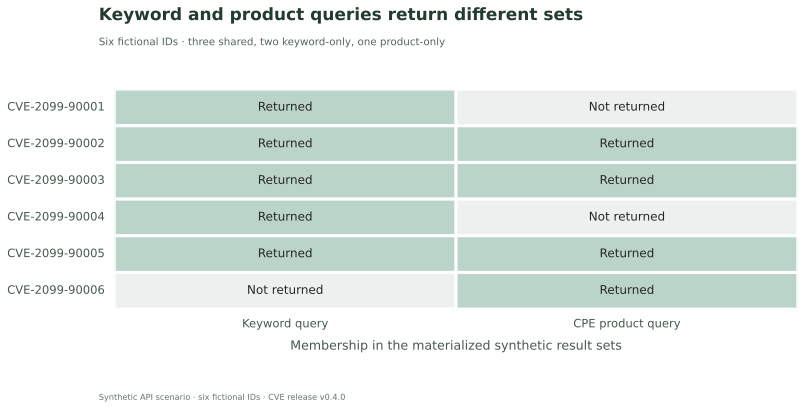

In [7]:
membership = globals()["membership"]
display(membership)
assert set(source.requests) == {r["id"] for r in source.manifest["records"]}
assert all(n == 1 for n in source.requests.values()) and not source.unexpected
prose(
    f"The worker made **{sum(source.requests.values())} page requests**, each once. "
    f"The union contains **{len(membership)} identifiers**: "
    f"**{int((membership.membership == 'Both queries').sum())}** shared, "
    f"**{int((membership.membership == 'Keyword only').sum())}** keyword-only and "
    f"**{int((membership.membership == 'Product only').sum())}** product-only. "
    "An intersection would discard a product-only candidate before any severity rule was applied."
)
fig, ax = plt.subplots(figsize=(10.8, 6.0))
values = membership[["keyword_member", "product_member"]].to_numpy(dtype=int)
sns.heatmap(
    values,
    annot=np.where(values, "Returned", "Not returned"),
    fmt="",
    cmap=ListedColormap(["#edf0ee", "#bad4ca"]),
    vmin=0,
    vmax=1,
    cbar=False,
    linewidths=3,
    linecolor="white",
    ax=ax,
    annot_kws={"fontsize": 12},
)
ax.set_xticklabels(["Keyword query", "CPE product query"], rotation=0)
ax.set_yticklabels(membership.id, rotation=0)
ax.set_xlabel("Membership in the materialized synthetic result sets")
ax.set_ylabel("")
finish(
    fig,
    "Keyword and product queries return different sets",
    "Six fictional IDs · three shared, two keyword-only, one product-only",
    source=SOURCE_LABEL,
    name="membership",
)

### Use product membership before applying the band cutoff

This review set begins with the four product-query rows, including the one absent
from the keyword result. Join nonmissing scores to the reference ranges, then use
the chosen lower band. Preserve raw severity text: released v0.4.0 returns an empty
string alongside an absent score; current source corrects that string to SQL NULL.
The explicit `Unscored` label below is derived from the numeric NULL, and the raw
column stays visible. Neither representation is converted into zero.

In [8]:
%%sql queue <<
SELECT p.cve_id AS id,p.cvss_score AS score,p.cvss_severity AS raw_severity,
 CASE WHEN p.cvss_score IS NULL THEN 'Unscored' ELSE b.severity END AS derived_band,
 p.cvss_score IS NOT NULL AND p.cvss_score >= chosen.min_score AS selected,
 chosen.min_score AS cutoff, chosen.severity AS lower_band
FROM product_results p
LEFT JOIN bands b ON p.cvss_score BETWEEN b.min_score AND b.max_score
CROSS JOIN boundary chosen
ORDER BY score DESC NULLS LAST,id;

,id,score,raw_severity,derived_band,selected,cutoff,lower_band
0,CVE-2099-90002,9.8,CRITICAL,CRITICAL,True,7.0,HIGH
1,CVE-2099-90003,7.5,HIGH,HIGH,True,7.0,HIGH
2,CVE-2099-90006,4.3,MEDIUM,MEDIUM,False,7.0,HIGH
3,CVE-2099-90005,NaN,,Unscored,False,7.0,HIGH


Starting at **HIGH (7)** selects **2 of 4** product-query records. **1** unscored record remains visible outside the numeric queue. Product membership and a severity band alone do not establish asset exposure or patch priority.

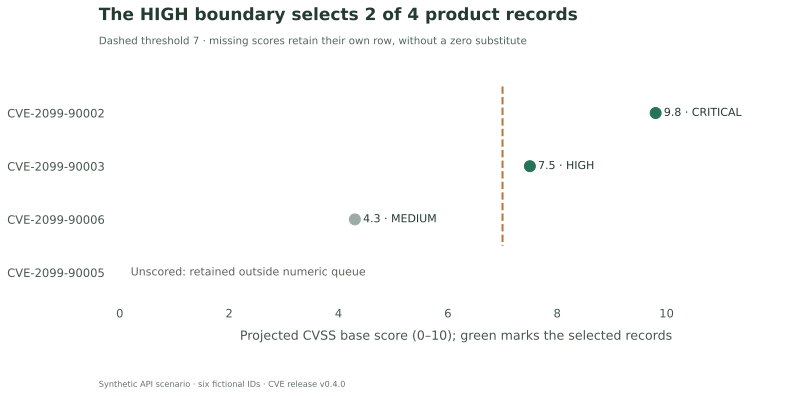

In [9]:
queue = globals()["queue"]
display(queue)
cutoff = float(queue.cutoff.iloc[0])
selected = queue[queue.selected]
prose(
    f"Starting at **{MIN_BAND} ({cutoff:g})** selects **{len(selected)} of {len(queue)}** "
    "product-query records. "
    f"**{int(queue.score.isna().sum())}** unscored record remains visible outside the numeric queue. "
    "Product membership and a severity band alone do not establish asset exposure or patch priority."
)
fig, ax = plt.subplots(figsize=(10.8, 5.8))
for y, row in enumerate(queue.itertuples(index=False)):
    if row.derived_band == "Unscored":
        ax.text(0.2, y, "Unscored: retained outside numeric queue", va="center", color="#675f57")
    else:
        ax.plot(row.score, y, "o", markersize=11, color="#267358" if row.selected else "#9eaba5")
        ax.text(row.score + 0.15, y, f"{row.score:.1f} · {row.derived_band}", va="center")
ax.vlines(cutoff, -0.5, len(queue) - 1.5, color="#b57440", linestyle="--", linewidth=2)
ax.set_yticks(range(len(queue)), queue.id)
ax.set_ylim(len(queue) - 0.5, -0.5)
ax.set_xlim(-0.1, 12.4)
ax.set_xticks(range(0, 11, 2))
ax.set_xlabel("Projected CVSS base score (0–10); green marks the selected records")
ax.grid(axis="y", visible=False)
finish(
    fig,
    f"The {MIN_BAND} boundary selects {len(selected)} of {len(queue)} product records",
    f"Dashed threshold {cutoff:g} · missing scores retain their own row, without a zero substitute",
    source=SOURCE_LABEL,
    name=f"queue-{MIN_BAND.lower()}",
)

### Verify grain, pagination and missingness

The fixed scenario gives explicit expected memberships. Check both page streams,
unique identifiers, shared-score agreement, the band join and the distinction
between a genuine zero and an absent score. Those assertions describe these synthetic
inputs; they are not a claim about the completeness of any live NVD search.

In [10]:
%%sql checks <<
SELECT 'Fixed keyword/product/union counts' AS check_name,
 abs((SELECT count(*) FROM keyword_results)-5)+abs((SELECT count(*) FROM product_results)-4)
 +abs((SELECT count(*) FROM keyword_results k FULL JOIN product_results p ON k.id=p.cve_id)-6) AS violations
UNION ALL SELECT 'No duplicate identifiers in either result',
 (SELECT count(*)-count(DISTINCT id) FROM keyword_results)+(SELECT count(*)-count(DISTINCT cve_id) FROM product_results)
UNION ALL SELECT 'Exactly three shared IDs',abs(count(*)-3)
 FROM keyword_results k JOIN product_results p ON k.id=p.cve_id
UNION ALL SELECT 'Shared assessments agree, including missing scores',count(*)
 FROM keyword_results k JOIN product_results p ON k.id=p.cve_id
 WHERE k.cvss_score IS DISTINCT FROM p.cvss_score OR k.cvss_severity IS DISTINCT FROM p.cvss_severity
UNION ALL SELECT 'Five bands and one chosen boundary',
 abs((SELECT count(*) FROM bands)-5)+abs((SELECT count(*) FROM boundary)-1)
UNION ALL SELECT 'Each observed score joins exactly one band',count(*) FROM (
 SELECT p.cve_id,count(b.severity) AS band_count FROM product_results p
 LEFT JOIN bands b ON p.cvss_score BETWEEN b.min_score AND b.max_score
 WHERE p.cvss_score IS NOT NULL GROUP BY p.cve_id HAVING count(b.severity)<>1)
UNION ALL SELECT 'One product record remains unscored',abs(count(*)-1) FROM product_results WHERE cvss_score IS NULL
UNION ALL SELECT 'Numeric zero remains distinct from missing',abs(count(*)-1)
 FROM keyword_results WHERE cvss_score=0 AND cvss_severity='NONE'
UNION ALL SELECT 'Product-only candidate is retained',abs(count(*)-1)
 FROM product_results p ANTI JOIN keyword_results k ON p.cve_id=k.id
UNION ALL SELECT 'Projected scores are bounded',count(*) FROM (
 SELECT cvss_score FROM keyword_results UNION ALL SELECT cvss_score FROM product_results)
 WHERE cvss_score IS NOT NULL AND (NOT isfinite(cvss_score) OR cvss_score<0 OR cvss_score>10);

In [11]:
checks = globals()["checks"]
display(checks)
assert (checks.violations == 0).all(), "Synthetic query-contract check failed."
assert len(queue) == 4 and queue.id.nunique() == 4
assert not queue.loc[queue.derived_band == "Unscored", "selected"].any()
prose(
    f"All **{len(checks)} SQL checks** pass. The local cutoff changes selection after fetching; "
    "it does not change the two request streams, union membership or missing-score count."
)
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-02.json").write_text(
    json.dumps(
        {
            "minimum_band": MIN_BAND,
            "membership": membership.to_dict("records"),
            "queue": queue.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": dict(source.requests),
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,violations
0,Fixed keyword/product/union counts,0
1,No duplicate identifiers in either result,0
2,Exactly three shared IDs,0
3,"Shared assessments agree, including missing sc...",0
4,Five bands and one chosen boundary,0
5,Each observed score joins exactly one band,0
6,One product record remains unscored,0
7,Numeric zero remains distinct from missing,0
8,Product-only candidate is retained,0
9,Projected scores are bounded,0


All **10 SQL checks** pass. The local cutoff changes selection after fetching; it does not change the two request streams, union membership or missing-score count.

3121

### One change to try

Change `MIN_BAND` from **HIGH** to **MEDIUM** and run all. Predict whether the
product-only record enters the queue. Compare the selected IDs and dashed line;
the membership figure, page audit, raw scores and unscored row should stay fixed.

```sh
uv run --locked vgi-notebooks 02_compare_keyword_and_product_membership.ipynb \
  --parameters '{"MIN_BAND":"MEDIUM"}' --output-dir artifacts/medium
```

No live mode is provided for fictional inputs. For actual public lookups use the
first notebook's explicit live mode, or form a separate recorded search with its
own provenance and completeness review. This example is not endorsed by NIST.

In [12]:
assert not con.execute("SELECT * FROM duckdb_secrets()").fetchall()
session.close()
source.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-cve](https://github.com/Query-farm/vgi-cve)